In [1]:
# import relevant packages
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torch.optim import SGD, Adam
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# load dataset
tr_fmnist = datasets.FashionMNIST(root='./data', train=True, download=False)
tr_images = tr_fmnist.data
tr_targets =tr_fmnist.targets

val_fmnist = datasets.FashionMNIST(root='./data', train=False, download=True)
val_images = val_fmnist.data
val_targets = val_fmnist.targets

In [3]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [4]:
class FMNISTDataset(Dataset):
    def __init__(self, x, y):
        x = x.float()/225
        x = x.view(-1, 28*28)
        self.x = x
        self.y = y
        
    def __len__(self):
        return len(self.x)
    
    def __getitem__(self, index):
        x = self.x[index]
        y = self.y[index]
        return x.to(device), y.to(device)

In [5]:
def getdata(data, target, size):
    dataset = FMNISTDataset(data, target)
    dataloader = DataLoader(dataset, batch_size=size, shuffle=True)
    return dataloader

In [6]:
def get_model():
    model = nn.Sequential(
        nn.Linear(28*28, 1000),
        nn.ReLU(),
        nn.Linear(1000, 10)
    ).to(device)
    loss = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=0.01)
    return model, loss, optimizer

In [7]:
def train_model(model, x, y, loss_fn, optimizer):
    model.train()
    predictions = model(x)
    loss_value = loss_fn(predictions, y)
    loss_value.backward()
    optimizer.step()
    optimizer.zero_grad()
    return loss_value.item()

def accuracy(model, x, y):
    model.eval()
    with torch.no_grad():
        prediction = model(x)
    max_value, argmax = prediction.max(-1)
    is_correct = argmax == y
    return is_correct.cpu().numpy().tolist()
    

### When Batch Size = 32

In [8]:

tr_dataloader = getdata(tr_images, tr_targets, 32)
val_dataloader = getdata(val_images, val_targets, len(val_images))

model, loss, optimizer = get_model()

In [9]:
@torch.no_grad()
def val_loss(x, y, model, loss_fn):
    model.eval()
    prediction = model(x)
    val_loss = loss_fn(prediction, y)
    return val_loss.item()

In [ ]:
# model training and evalution
tr_losses, tr_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(5):
    print(epoch)
    epoch_losses, epoch_accuracies = [], []
    for ix, batch in enumerate(iter(tr_dataloader)):
        x, y = batch
        batch_loss = train_model(model, x, y, loss, optimizer)
        epoch_losses.append(batch_loss)
    epoch_loss = np.array(epoch_losses).mean()
    print(f"Epoch {epoch}: loss = {epoch_loss}")
    
    for ix, batch in enumerate(iter(tr_dataloader)):
        x, y = batch
        is_correct = accuracy(model, x, y)
        epoch_accuracies.extend(is_correct)
    epoch_accuracy = np.mean(epoch_accuracies)
    print(f"Epoch {epoch}: accuracy = {epoch_accuracy}")
    
    for ix, batch in enumerate(iter(val_dataloader)):
        x, y = batch
        val_is_correct = accuracy(model, x, y)
        validation_loss = val_loss(x, y, model, loss)
    val_epoch_accuracy = np.mean(val_is_correct)
    print(f"validation Loss: {validation_loss}")
    
    tr_losses.append(epoch_loss)
    tr_accuracies.append(epoch_accuracy)
    val_losses.append(validation_loss)
    val_accuracies.append(val_epoch_accuracy)
    
    
        

0
Epoch 0: loss = 0.547064293440183
Epoch 0: accuracy = 0.8166833333333333
validation Loss: 0.8025
1
Epoch 1: loss = 0.4363287920554479
Epoch 1: accuracy = 0.84845
validation Loss: 0.8322
2
Epoch 2: loss = 0.4180620084842046
Epoch 2: accuracy = 0.8601
validation Loss: 0.8418
3
Epoch 3: loss = 0.4075163704355558
Epoch 3: accuracy = 0.8412166666666666
validation Loss: 0.8277
4
Epoch 4: loss = 0.3977317475795746
Epoch 4: accuracy = 0.8561666666666666
validation Loss: 0.8383


In [12]:
import matplotlib.ticker as mtick
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
%matplotlib inline

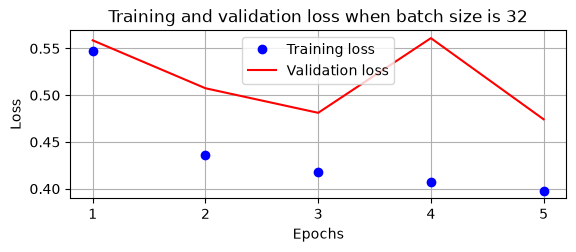

C:\Users\pomaa\AppData\Local\Temp\ipykernel_37680\2344007671.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  plt.gca().set_yticklabels(['{:.0f}%'.format(x*100) \


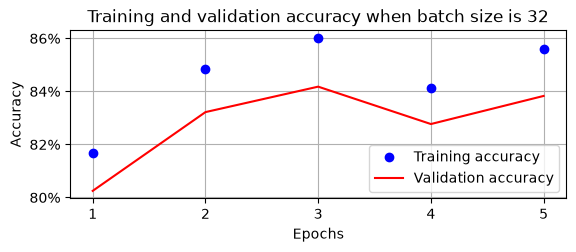

In [ ]:
epoch = np.arange(5)+1
plt.subplot(211)
plt.plot(epoch, tr_losses, 'bo', label='Training loss')
plt.plot(epoch, val_losses, 'r', label='Validation loss')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title('Training and validation loss when batch size is 32')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid('off')
plt.show()
plt.subplot(212)
plt.plot(epoch, tr_accuracies, 'bo',label='Training accuracy')
plt.plot(epoch, val_accuracies, 'r', label='Validation accuracy')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title('Training and validation accuracy when batch size is 32')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.gca().set_yticklabels(['{:.0f}%'.format(x*100) \
                           for x in plt.gca().get_yticks()]) 
plt.legend()
plt.grid('off')
plt.show()

### When batch size = 10,000 

In [14]:
tr_dataloader = getdata(tr_images, tr_targets, 10000)
val_dataloader = getdata(val_images, val_targets, len(val_images))

model, loss, optimizer = get_model()

In [15]:
# model training and evalution
tr_losses, tr_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(5):
    print(epoch)
    epoch_losses, epoch_accuracies = [], []
    for ix, batch in enumerate(iter(tr_dataloader)):
        x, y = batch
        batch_loss = train_model(model, x, y, loss, optimizer)
        epoch_losses.append(batch_loss)
    epoch_loss = np.array(epoch_losses).mean()
    print(f"Epoch {epoch}: loss = {epoch_loss}")
    
    for ix, batch in enumerate(iter(tr_dataloader)):
        x, y = batch
        is_correct = accuracy(model, x, y)
        epoch_accuracies.extend(is_correct)
    epoch_accuracy = np.mean(epoch_accuracies)
    print(f"Epoch {epoch}: accuracy = {epoch_accuracy}")
    
    for ix, batch in enumerate(iter(val_dataloader)):
        x, y = batch
        val_is_correct = accuracy(model, x, y)
        validation_loss = val_loss(x, y, model, loss)
    val_epoch_accuracy = np.mean(val_is_correct)
    print(f"validation Loss: {validation_loss}")
    
    tr_losses.append(epoch_loss)
    tr_accuracies.append(epoch_accuracy)
    val_losses.append(validation_loss)
    val_accuracies.append(val_epoch_accuracy)
    
    
        

0
Epoch 0: loss = 4.4489980936050415
Epoch 0: accuracy = 0.4723
validation Loss: 2.0337886810302734
1
Epoch 1: loss = 1.314569483200709
Epoch 1: accuracy = 0.6739166666666667
validation Loss: 0.8911703824996948
2
Epoch 2: loss = 0.7653719186782837
Epoch 2: accuracy = 0.7484666666666666
validation Loss: 0.7089025378227234
3
Epoch 3: loss = 0.6312744915485382
Epoch 3: accuracy = 0.7934
validation Loss: 0.6005331873893738
4
Epoch 4: loss = 0.5430862406889597
Epoch 4: accuracy = 0.8169666666666666
validation Loss: 0.5383065342903137


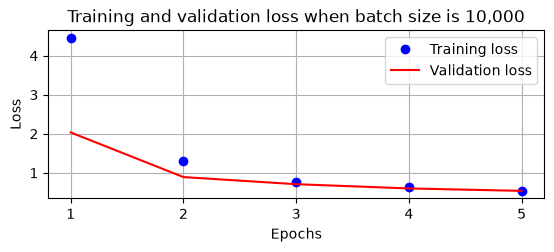

C:\Users\pomaa\AppData\Local\Temp\ipykernel_37680\4112957006.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  plt.gca().set_yticklabels(['{:.0f}%'.format(x*100) \


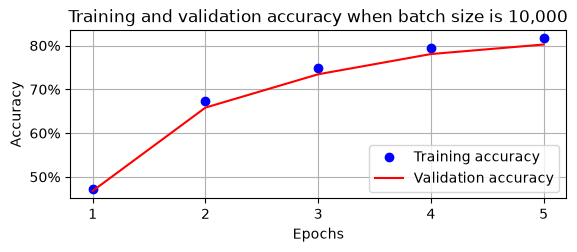

In [17]:
epoch = np.arange(5)+1
plt.subplot(211)
plt.plot(epoch, tr_losses, 'bo', label='Training loss')
plt.plot(epoch, val_losses, 'r', label='Validation loss')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title('Training and validation loss when batch size is 10,000')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid('off')
plt.show()
plt.subplot(212)
plt.plot(epoch, tr_accuracies, 'bo',label='Training accuracy')
plt.plot(epoch, val_accuracies, 'r', label='Validation accuracy')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title('Training and validation accuracy when batch size is 10,000')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.gca().set_yticklabels(['{:.0f}%'.format(x*100) \
                           for x in plt.gca().get_yticks()]) 
plt.legend()
plt.grid('off')
plt.show()